In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from PIL import Image
import cv2
import os

# Add label class chili

In [2]:
def segm(img, threshold=56):
    # print(type(img))
    img = img.copy()
    img = np.array(img)
    img = np.where(img >= threshold, 255, 0)

    return img
    
def get_mask(img,threshold = 16, use_closing = True, use_contour = True):
        img = img
        # cv2.imshow("", img)
        # cv2.imshow("2", img)
        
        img_red = np.array(img[:, :, 0])
        hist = cv2.calcHist([img_red], [0], None, [256], [0, 256])

        fruit_mask = segm(img_red, hist.argmax() + threshold)
        fruit_mask = fruit_mask.astype(np.uint8)
        # cv2.imshow("3", fruit_mask)

        if use_closing:
            kernel = np.ones((10, 10), np.uint8)
            fruit_mask = cv2.morphologyEx(fruit_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
            fruit_mask = fruit_mask.astype(np.uint8)
        # cv2.imshow("4", fruit_mask)
        if use_contour:
            contours, hierarchy = cv2.findContours(fruit_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            contour_areas = [cv2.contourArea(cnt) for cnt in contours]
            max_area = max(contour_areas)
            fruit_mask = np.zeros_like(fruit_mask)
            contour_line = np.zeros_like(fruit_mask)
            for cnt in contours:
                area = cv2.contourArea(cnt)
                if area >= max_area:
                    cv2.drawContours(fruit_mask, [cnt], -1, (255, 255, 255), -1)
 
        return fruit_mask

def find_center(cnt):
    centroid_x = sum(x for x, y in cnt) / len(cnt)
    centroid_y = sum(y for x, y in cnt) / len(cnt)
    return centroid_x, centroid_y

In [3]:
with open('./data/001_IT135673_1.json', "r", encoding="utf-8") as f:
    data = json.load(f)

In [4]:
data.keys()

dict_keys(['version', 'flags', 'shapes', 'imagePath', 'imageData', 'imageHeight', 'imageWidth'])

In [5]:
data['shapes'][0]

{'label': 'seed',
 'text': '',
 'points': [[642.7083333333334, 1379.1666666666667],
  [648.4375, 1395.8333333333335],
  [644.2708333333334, 1416.6666666666667],
  [647.3958333333334, 1426.0416666666667],
  [633.3333333333334, 1429.1666666666667],
  [615.625, 1418.75],
  [611.4583333333334, 1401.5625],
  [615.625, 1388.0208333333335],
  [625.5208333333334, 1380.2083333333335]],
 'group_id': None,
 'shape_type': 'polygon',
 'flags': {}}

In [6]:
ep = 0.003

def mask_img(img_path):
    img = cv2.imread(img_path)
    img_RGB = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # plt.imshow(img_RGB)
    # plt.show()
    img_red = img_RGB[540:, :, 0]
    # cv2_imshow(img_red)
    # plt.imshow(img_red)
    # plt.show()
    img_mask = get_mask(img_RGB[540:, :, :], 22 , True, False)
    # cv2_imshow(img_mask)
    # plt.imshow(img_mask)
    # plt.show()
    
    contours, hierarchy = cv2.findContours(img_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour_areas = [cv2.contourArea(cnt) for cnt in contours]
    max_area = max(contour_areas)
    fruit_mask = img_RGB[540:, :, :]
    masks = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area >= 10000:
            # print(cnt)
            # masks.append(cnt)
            cv2.drawContours(fruit_mask, [cnt], -1, (255, 255, 255), 2)
            length_L1 = cv2.arcLength(cnt, True)
            cnt = cv2.approxPolyDP(cnt, ep*length_L1, True)
            contour = [p[0].tolist() for p in cnt]
            contour_or = [[p[0],p[1]+540] for p in contour]
            masks.append(contour_or)
    
    # plt.imshow(fruit_mask)
    # plt.show()
    return masks
    

# set data coco

In [7]:
# import random 

# ep= 0.003
# folder_path = '/kaggle/input/jeju-segmentation/jeju_segmentation'
# save_js = '/kaggle/working/json'
# os.makedirs(save_js, exist_ok=True)
# jpg_files = [f for f in os.listdir(folder_path) if f.endswith(".jpg")]

# for img_name in jpg_files:
#     name = name = os.path.splitext(img_name)[0]
#     img_path = os.path.join(folder_path, img_name)
#     contours = mask_img(img_path)
#     js_path = os.path.join(folder_path, name + '.json')
#     save_js_path = os.path.join(save_js, name + '.json')
#     # bboxs = []
#     if not os.path.exists(js_path):
#         img = cv2.imread(img_path)
#         height, width, channels = img.shape
#         data = {
#             "version": "0.4.29",
#             "flags": {},
#             "shapes": [],
#             "imagePath": img_name,
#             "imageData": None,
#             "imageHeight": height,
#             "imageWidth": width,
#             "text": ""
#         }
#     else:
#         with open(js_path, "r", encoding="utf-8") as f:
#             data = json.load(f)
#     for contour in contours:
#         # x, y, w, h = cv2.boundingRect(cnt)
#         # bboxes.append((x, y, w, h))
#         obj = {
#             "label": "chili",
#              "text": "",
#              "points": contour,
#              "group_id": None,
#              "shape_type": "polygon",
#              "flags": {}
#         }
#         data['shapes'].append(obj)

#     with open(save_js_path, "w", encoding="utf-8") as f:
#         json.dump(data, f, ensure_ascii=False, indent=4)
    



In [8]:
# # jpg_files[:20]
# for img_name in [jpg_files[0]]:
#     img_path = os.path.join(folder_path, img_name)
#     masks = mask_img(img_path)
#     # flattened = [p[0] for p in [p for p in masks]]
#     # print(masks)

# Cut chili data

In [9]:
# ep= 0.003
# masks = mask_img('/kaggle/input/jeju-segmentation/jeju_segmentation/001_IT113643_1.jpg')
# image = cv2.imread('/kaggle/input/jeju-segmentation/jeju_segmentation/001_IT113643_1.jpg')


# for i, mask in enumerate(masks):
#     x, y, w, h = cv2.boundingRect(np.array(mask))
#     # print(x,y,w,h)
#     img = image[y-50:y+h+50, x-50:x+w+50]
#     # cv2.imwrite("output.jpg", img)
#     cv2_imshow(img)
#     cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

# cv2_imshow(image)

# Convert format data to yolo format

In [10]:
import shutil
import random


folder_path = '/kaggle/input/jeju-segmentation/jeju_segmentation'
save_text = '/kaggle/working/dataset/labels'
save_img = '/kaggle/working/dataset/images'
pre_img_path = '/kaggle/working/pre_imgs'
data_name = ['train', 'val', 'test']
map_label = {'seed': 0, 'outer': 1, 'placenta': 2, 'endocarp': 3, 'chili': 4}

os.makedirs(save_text, exist_ok=True)
os.makedirs(save_img, exist_ok=True)
os.makedirs(pre_img_path, exist_ok=True)
for i in data_name:
    img_path = os.path.join(save_img, i)
    os.makedirs(img_path, exist_ok=True)
    label_path = os.path.join(save_text, i)
    os.makedirs(label_path, exist_ok=True)
    
img_files = [f for f in os.listdir(folder_path) if f.endswith(".jpg")]
js_files = [f for f in os.listdir(folder_path) if f.endswith(".json")]

for js_file in js_files:
    name = js_file.split(".")[0]
    img_path = os.path.join(folder_path, name + ".jpg")
    js_path = os.path.join(folder_path, js_file)
    # des_img = os.path.join(save_img, f"train/{name}.jpg")
    # shutil.copy(img_path, des_img)
    image = cv2.imread(img_path)
    masks = mask_img(img_path)
    # print(img.shape)
    with open(js_path, "r") as f:
        data_coco = json.load(f)
    # data_yolo = []
    # for obj in data_coco['shapes']:
    #     data = f"{map_label[obj['label']]}"
    #     for point in obj['points']:
    #         data += f" {point[0]/image.shape[1]} {point[1]/image.shape[0]}"

    #     data += '\n'
    #     data_yolo.append(data)
        
    for i, mask in enumerate(masks):
        x, y, w, h = cv2.boundingRect(np.array(mask))
        # print(x,y,w,h)
        img = image[max(0,y-50):min(image.shape[0],y+h+50), max(0,x-50):min(image.shape[1],x+w+50)]
        text_path = os.path.join(save_text, f"train/{name}_{i}.txt")
        data_yolo = []
        for obj in data_coco['shapes']:
            pol = obj['points']
            center = find_center(pol)
            if center[1] >= y-50 and center[1] <= y+h+50 and center[0] >= x-50 and center[0] <= x+w+50:
                # print(i)
                data = f"{map_label[obj['label']]}"
                for point in pol:
                    data += f" {(point[0]-x+50)/img.shape[1]} {(point[1]-y+50)/img.shape[0]}"
                data += '\n'
                data_yolo.append(data)

        if data_yolo != []:
            cv2.imwrite(os.path.join(save_img, f"train/{name}_{i}.jpg"), img)
            with open(text_path, "w", encoding="utf-8") as f:
                for data in data_yolo:
                    f.write(data)

for js_file in random.sample(js_files, 40):
    name = js_file.split(".")[0]
    img_path = os.path.join(folder_path, name + ".jpg")
    js_path = os.path.join(folder_path, js_file)
    image = cv2.imread(img_path)
    masks = mask_img(img_path)
    # print(img.shape)
    with open(js_path, "r") as f:
        data_coco = json.load(f)
   
        
    for i, mask in enumerate(masks):
        x, y, w, h = cv2.boundingRect(np.array(mask))
        # print(x,y,w,h)
        img = image[max(0,y-50):min(image.shape[0],y+h+50), max(0,x-50):min(image.shape[1],x+w+50)]
        cv2.imwrite(os.path.join(save_img, f"val/{name}_{i}.jpg"), img)
        text_path = os.path.join(save_text, f"val/{name}_{i}.txt")
        data_yolo = []
        for obj in data_coco['shapes']:
            pol = obj['points']
            center = find_center(pol)
            if center[1] >= y-50 and center[1] <= y+h+50 and center[0] >= x-50 and center[0] <= x+w+50:
                # print(i)
                data = f"{map_label[obj['label']]}"
                for point in pol:
                    data += f" {(point[0]-x+50)/img.shape[1]} {(point[1]-y+50)/img.shape[0]}"
                data += '\n'
                data_yolo.append(data)
        
        with open(text_path, "w", encoding="utf-8") as f:
            for data in data_yolo:
                f.write(data)

for js_file in random.sample(js_files, 60):
    name = js_file.split(".")[0]
    img_path = os.path.join(folder_path, name + ".jpg")
    js_path = os.path.join(folder_path, js_file)
    image = cv2.imread(img_path)
    masks = mask_img(img_path)
    # print(img.shape)
    with open(js_path, "r") as f:
        data_coco = json.load(f)
   
        
    for i, mask in enumerate(masks):
        x, y, w, h = cv2.boundingRect(np.array(mask))
        # print(x,y,w,h)
        img = image[max(0,y-50):min(image.shape[0],y+h+50), max(0,x-50):min(image.shape[1],x+w+50)]
        cv2.imwrite(os.path.join(save_img, f"test/{name}_{i}.jpg"), img)
        text_path = os.path.join(save_text, f"test/{name}_{i}.txt")
        data_yolo = []
        for obj in data_coco['shapes']:
            pol = obj['points']
            center = find_center(pol)
            if center[1] >= y-50 and center[1] <= y+h+50 and center[0] >= x-50 and center[0] <= x+w+50:
                # print(i)
                data = f"{map_label[obj['label']]}"
                for point in pol:
                    data += f" {(point[0]-x+50)/img.shape[1]} {(point[1]-y+50)/img.shape[0]}"
                data += '\n'
                data_yolo.append(data)
        
        with open(text_path, "w", encoding="utf-8") as f:
            for data in data_yolo:
                f.write(data)

# get img not label to predict
for img_file in img_files:
    name = img_file.split(".")[0]
    img_path = os.path.join(folder_path, img_file)
    js_path = os.path.join(folder_path, name+'.json')
    if not os.path.exists(js_path):
        image = cv2.imread(img_path)
        masks = mask_img(img_path)
        
        for i, mask in enumerate(masks):
            x, y, w, h = cv2.boundingRect(np.array(mask))
            # print(x,y,w,h)
            img = image[max(0,y-50):min(image.shape[0],y+h+50), max(0,x-50):min(image.shape[1],x+w+50)]
            try:
                cv2.imwrite(os.path.join(pre_img_path, f"{name}_{i}.jpg"), img)
            except Exception as e:
                print(img)
                print("❌ Error:", e)
        
# for js_file in js_files[:10]:
#     name = js_file.split(".")[0]
#     img_path = os.path.join(folder_path, name + ".jpg")
#     js_path = os.path.join(folder_path, js_file)
#     des_img = os.path.join(save_img, f"val/{name}.jpg")
#     shutil.copy(img_path, des_img)
#     img = cv2.imread(img_path)
#     text_path = os.path.join(save_text, f"val/{name}.txt")

#     # print(img.shape)
#     with open(js_path, "r") as f:
#         data_coco = json.load(f)
#     data_yolo = []
#     for obj in data_coco['shapes']:
#         data = f"{map_label[obj['label']]}"
#         for point in obj['points']:
#             data += f" {point[0]/img.shape[1]} {point[1]/img.shape[0]}"

#         data += '\n'
#         data_yolo.append(data)
        
#     with open(text_path, "w", encoding="utf-8") as f:
#         for data in data_yolo:
#             f.write(data)


# Show contour

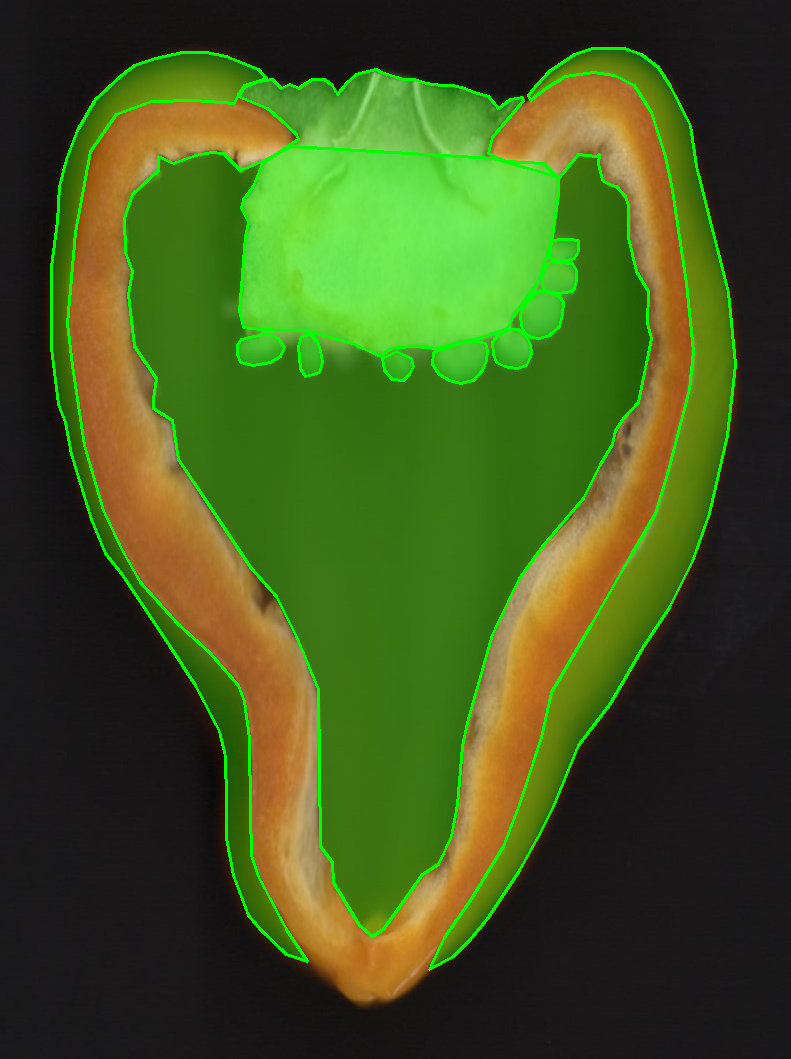

In [11]:
import cv2
import numpy as np

# ==== ĐƯỜNG DẪN ====
img_path = "/kaggle/working/dataset/images/train/290_IT236451_2_1.jpg"
label_path = "/kaggle/working/dataset/labels/train/290_IT236451_2_1.txt"

# ==== ĐỌC ẢNH ====
img = cv2.imread(img_path)
h, w = img.shape[:2]

# ==== ĐỌC FILE LABEL ====
with open(label_path, "r") as f:
    lines = f.readlines()

for line in lines:
    parts = line.strip().split()
    cls_id = int(parts[0])                # class id
    coords = np.array(parts[1:], dtype=float).reshape(-1, 2)
    
    # Chuyển tọa độ chuẩn hóa sang pixel thật
    coords[:, 0] *= w
    coords[:, 1] *= h
    coords = coords.astype(int)

    # Vẽ polygon (đường viền)
    cv2.polylines(img, [coords], isClosed=True, color=(0, 255, 0), thickness=2)

    # Tô màu vùng polygon (nếu muốn)
    overlay = img.copy()
    cv2.fillPoly(overlay, [coords], color=(0, 255, 0))
    img = cv2.addWeighted(overlay, 0.3, img, 0.7, 0)

# ==== HIỂN THỊ ====
cv2_imshow(img)


In [12]:
# Create data jam
import yaml
from pathlib import Path

# Configuration
dataset_dir = Path("/kaggle/working/dataset")
data = {
    "train": str(dataset_dir / "images/train"),
    "val": str(dataset_dir / "images/val"),
    "nc": 4,
    "names": ['seed', 'outer', 'placenta', 'endocarp']
}

# Save YAML file
with open(dataset_dir / "data.yaml", "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("✅ data.yaml created successfully!")


✅ data.yaml created successfully!


# Predict unlabel data

In [13]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 74.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [14]:
!yolo --version

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
WARNING ⚠️ argument '--version' does not require leading dashes '--', updating to 'version'.
8.3.221


In [15]:
%cd /kaggle/working

/kaggle/working


In [16]:
# !yolo task=segment mode=train model=yolov8m-seg.pt data=dataset/data.yaml epochs=100 imgsz=640

In [17]:
!yolo task=segment mode=predict model=/kaggle/input/chili-dataset-segment/runs/segment/train/weights/best.pt source=pre_imgs save_txt = True

Ultralytics 8.3.221 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
YOLOv8m-seg summary (fused): 105 layers, 27,224,700 parameters, 0 gradients, 104.3 GFLOPs

image 1/1422 /kaggle/working/pre_imgs/002_IT113703_1_0.jpg: 640x448 (no detections), 51.7ms
image 2/1422 /kaggle/working/pre_imgs/002_IT113703_1_1.jpg: 576x640 (no detections), 51.0ms
image 3/1422 /kaggle/working/pre_imgs/002_IT113703_1_2.jpg: 640x256 8 seeds, 1 placenta, 1 endocarp, 66.7ms
image 4/1422 /kaggle/working/pre_imgs/002_IT113703_1_3.jpg: 640x256 13 seeds, 2 placentas, 1 endocarp, 13.6ms
image 5/1422 /kaggle/working/pre_imgs/002_IT113703_1_4.jpg: 640x224 9 seeds, 1 placenta, 1 endocarp, 59.7ms
image 6/1422 /kaggle/working/pre_imgs/002_IT113703_1_5.jpg: 640x256 22 seeds, 1 placenta, 1 endocarp, 14.6ms
image 7/1422 /kaggle/working/pre_imgs/002_IT113703_1_6.jpg: 640x224 6 seeds, 1 placenta, 1 endocarp, 13.0ms
image 8/1422 /kaggle/working/pre_imgs/002_IT113703_1_7.jpg: 640x256 21 seeds, 2 placent

# apply SAHI 

In [18]:
# !pip install -q torch sahi yolov8 ultralytics numpy opencv-python

In [19]:
# # from sahi.utils.yolov8 import (
# #     download_yolov8s_model,
# # )

# # Create model
# from sahi import AutoDetectionModel

# # Ultil to read, dowwnload image
# from sahi.utils.cv import read_image
# from sahi.utils.file import download_from_url

# # Prediction
# from sahi.predict import get_prediction, get_sliced_prediction, predict
# from sahi.prediction import visualize_object_predictions

# # Ultils
# from IPython.display import Image
# from numpy import asarray
# import cv2
     

In [20]:
# from sahi.model import Yolov8DetectionModel
# from sahi.predict import get_sliced_prediction
# from sahi.utils.cv import read_image

# # --- Load YOLOv8 segmentation model ---
# model_path = "runs/segment/train/weights/best.pt"
# detection_model = Yolov8DetectionModel(
#     model_path=model_path,
#     confidence_threshold=0.4,
#     device="cuda:0"  # or "cpu"
# )

# # --- Load large image ---
# image = read_image("/kaggle/input/jeju-segmentation/jeju_segmentation/001_IT113643_1.jpg")

# # --- Run SAHI slicing prediction ---
# result = get_sliced_prediction(
#     image=image,
#     detection_model=detection_model,
#     slice_height=640,
#     slice_width=640,
#     overlap_height_ratio=0.2,
#     overlap_width_ratio=0.2
# )

# # --- Save visualization ---
# result.export_visuals(export_dir="sahi_results/")

# Show result

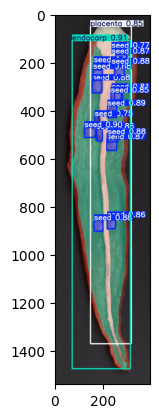

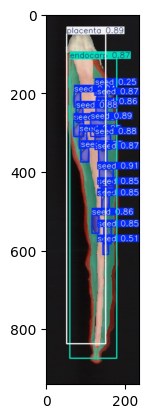

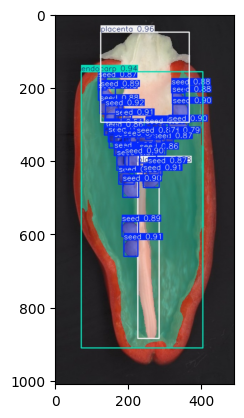

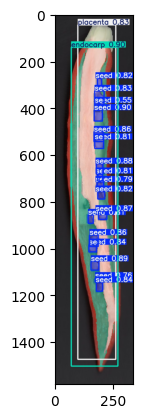

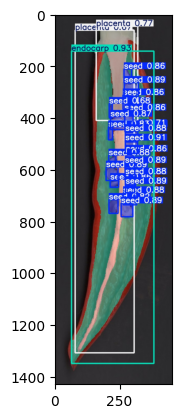

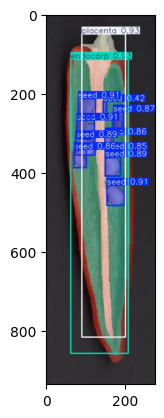

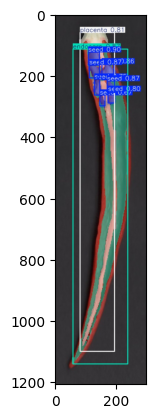

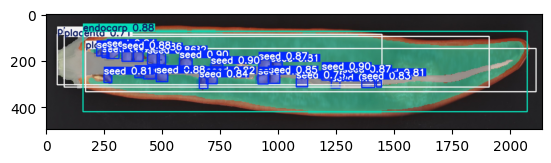

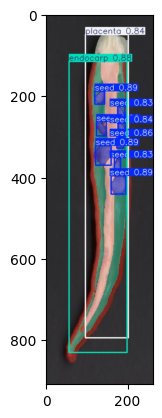

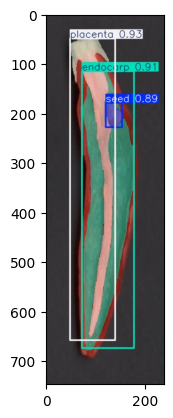

In [21]:
import cv2
from matplotlib import pyplot as plt

path = "/kaggle/working/runs/segment/predict"
imgs = os.listdir(path)
for name in random.sample(imgs,10):
    img_path = os.path.join(path, name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.show()